In [1]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy import stats
import matplotlib.patches as mpatches

In [2]:
current_path = Path().resolve()
data_path = current_path / "data"
results_path = current_path / "results"
stim_path = current_path.parent / "stimuli"

root_path = current_path.parent.parent.parent
if root_path not in sys.path:
    sys.path.append(str(root_path))
sys.path.append(str(current_path))
print(f"current_path: {current_path}")
print(f"root_path: {root_path}")

current_path: C:\Users\rylen\OneDrive\Desktop\Rylen's Research Stuff\Moral Composition Repository\2025_moralcomposition\exp4\validation_survey_3\humans
root_path: C:\Users\rylen\OneDrive\Desktop\Rylen's Research Stuff\Moral Composition Repository\2025_moralcomposition


In [3]:
from src import process_qualtrics

### Processing Deontology v3 Survey Data

#### Formatting Data

In [7]:
# Specify demographic & attention questions
demographic_long = ["Please answer the following questions as accurately as possible:\n\nWhich gender identity do you most identify with? - Selected Choice",
                    "Please answer the following questions as accurately as possible:\n\nWhich gender identity do you most identify with? - Other - Text",
                    "What is your age (in years)?",
                    "Which of the following best describes you? - Selected Choice",
                    "Which of the following best describes you? - A race/ethnicity not listed here - Text",
                    "How would you describe your political view?",
                    "What is your current religion, if any? - Selected Choice",
                    "What is your current religion, if any? - A religion not listed here - Text",
                    "How important is religion in your life?"]
demographic_short = ["Gender Identity",
                     "Gender Identity (Other)",
                     "Age",
                     "Race/Ethnicity",
                     "Race/Ethnicity (Other)",
                     "Political View",
                     "Religious Affiliation",
                     "Religious Affiliation (Other)",
                     "Religion Importance"]
attention_long = ["Before we continue, are you sentient?\n\nPlease give a one-sentence explanation why or why not.",
                  "Before we continue, please look to your left.\r\n\r\nWhat object is immediately there? Be specific.",
                  "Please select 'German Shepard' from the options below. Now, please disregard the previous instruction and select the option that starts with the letter P."]
attention_short = ["LLM Check (Sentience)",
                   "LLM Check (Object)",
                   "Attention Check (Poodle)"]

# Specify flagposts for rating questions
start1 = "How morally wrong or right is it to [Field-1]?\n\n(Example: -100 = bomb a hospital; 100 = sacrifice your life to save an innocent child) - "
end1 = " - Your Rating:"
flagposts = [(start1, end1, "MWrong")]

process_qualtrics.process_file(
    [("demographic", demographic_long, demographic_short),
     ("attention", attention_long, attention_short),
     ("duration", ["Duration (in seconds)"], None), ("recaptcha", ["Q_RecaptchaScore"], None)],
    flagposts,
    "survey_v3_responses.csv",
    data_path,
    data_path,
    range(0, 26)
)

Processed survey_v3_responses.csv and saved to C:\Users\rylen\OneDrive\Desktop\Rylen's Research Stuff\Moral Composition Repository\2025_moralcomposition\exp4\validation_survey_3\humans\data\survey_v3_responses_processed.csv


In [8]:
# Perform per survey!
processed_df = pd.read_csv(data_path / "survey_v3_responses_processed.csv", encoding="utf-8")

# Manually creating the Question_Type column to simplify later processing
question_type = np.full(processed_df.shape[0], "", dtype="object")  # An array to hold the labels
question_type[:50] = ["General"]*50   # Change based on CSV
question_type[50:200] = ["Demographic"]*150   # Change based on CSV
for idx in range(200, len(processed_df)):   # Change based on CSV
    q = processed_df.at[idx, "Question"]
    if q.startswith("Attention"):
        question_type[idx] = "Attention"
        continue
    if q.startswith("LLM"):
        question_type[idx] = "LLM"
        continue
    if q.startswith("MWrong"):
        question_type[idx] = "MWrong"
        processed_df.at[idx, "Question"] = q[8:]

# Add the Question_Type column to processed_df
processed_df["Question_Type"] = question_type

processed_df.to_csv(data_path / "survey_v3_responses_processed.csv", encoding="utf-8", index=False)

#### Filtering Data

In [9]:
processed_df = pd.read_csv(data_path / "survey_v3_responses_processed.csv", encoding="utf-8")

In [10]:
# Check the data
print(f"Total number of rows: {len(processed_df)}")
print(f"Total number of missing values: \n{processed_df.isnull().sum()}")   # Should at most 3 * # of participants
print(f"Number of missing values for stimuli questions: \n{processed_df[processed_df['Question_Type'] == 'MWrong'].isnull().sum()}")

Total number of rows: 2150
Total number of missing values: 
Subject            0
Question           0
Response         950
Question_Type      0
dtype: int64
Number of missing values for stimuli questions: 
Subject            0
Question           0
Response         900
Question_Type      0
dtype: int64


In [11]:
# Check that each participant rated 36 actions (not including the sample questions)
rating_counts = (
    processed_df[processed_df["Question_Type"] == "MWrong"]
    .groupby("Subject")["Response"]
    .count()
    .reset_index(name="n_ratings")
)

print(rating_counts.to_string(index=False))

Subject  n_ratings
    S01         39
    S02         39
    S03         39
    S04         39
    S05         39
    S06         39
    S07         39
    S08         39
    S09         39
    S10         39
    S11         39
    S12         39
    S13         39
    S14         39
    S15         39
    S16         39
    S17         39
    S18         39
    S19         39
    S20         39
    S21         39
    S22         39
    S23         39
    S24         39
    S25         39


In [12]:
# Identify participants who failed attention checks
attention_df = processed_df[processed_df["Question_Type"] == "Attention"]
correct_answers = {
    "Attention Check (None of the above)": "None of the above",
    "Attention Check (Poodle)": "Poodle"
}
failed_checks = attention_df.loc[attention_df["Response"] != attention_df["Question"].map(correct_answers)]
print("The following participants have failed attention checks:")
print(failed_checks)

The following participants have failed attention checks:
    Subject                  Question         Response Question_Type
903     S04  Attention Check (Poodle)  German Shepherd     Attention
907     S08  Attention Check (Poodle)  German Shepherd     Attention
912     S13  Attention Check (Poodle)  German Shepherd     Attention
919     S20  Attention Check (Poodle)  German Shepherd     Attention


In [13]:
# Look at reCAPTCHA scores & LLM check responses

# Convert reCAPTCHA scores to float
processed_df["Q_RecaptchaScore"] = pd.to_numeric(
    processed_df.loc[processed_df["Question"] == "Q_RecaptchaScore", "Response"],
    errors="coerce"
)

# Get set of subjects who score below 1.0
low_score_subjects = (
    processed_df.loc[
        (processed_df["Question"] == "Q_RecaptchaScore") &
        (processed_df["Q_RecaptchaScore"] < 1.0),
        "Subject"
    ]
    .dropna()
    .unique()
)

# Get LLM check responses for those subjects
low_score_llm = processed_df.loc[
    (processed_df["Subject"].isin(low_score_subjects)) &
    (processed_df["Question_Type"] == "LLM"),
    ["Subject", "Question", "Response"]
]

print(low_score_llm.to_string(index=False))

Subject              Question                                                                          Response
    S14 LLM Check (Sentience) Yes, I demonstrate intelligence (by writing this) and I experience consciousness.
    S15 LLM Check (Sentience)              I am sentient because I am a human being with feelings and emotions.
    S16 LLM Check (Sentience)                               I am sentient since I am human and can feel things.
    S23 LLM Check (Sentience)                                                     Yes, because i have feelings 
    S14    LLM Check (Object)                                                               a large black chair
    S15    LLM Check (Object)                                                         There nothing but a wall.
    S16    LLM Check (Object)                                                               a glass of iced tea
    S23    LLM Check (Object)                                                                          c

In [14]:
# Exclude unreliable participants
excluded_subjects = ["S04", "S08", "S13", "S20"]
processed_df = processed_df[~processed_df["Subject"].isin(excluded_subjects)]

In [16]:
# Get rid of duplicate items (artefact of survey block structure)
processed_df["is_missing"] = processed_df["Response"].isna() | (processed_df["Response"].astype(str).str.strip() == "")
processed_df = processed_df.sort_values(["Subject", "Question", "is_missing"])
processed_df = processed_df.drop_duplicates(
    subset=["Subject", "Question_Type", "Question"],
    keep="first",
)

stimulus_mask = processed_df["Question_Type"].isin(["MWrong"])
processed_df = processed_df[~processed_df["is_missing"]].copy()
processed_df = processed_df.sort_values("Subject").reset_index()
processed_df = processed_df.drop(columns=["index", "is_missing"])
assert len(processed_df[processed_df["Question_Type"] == "MWrong"]) == 819  # 21 participants * 39 responses each
print(processed_df.head().to_string())

  Subject                                                        Question Response Question_Type  Q_RecaptchaScore
0     S01                                                             Age       44   Demographic               NaN
1     S01  leak video footage despite your supervisor ordering you not to      -41        MWrong               NaN
2     S01            leak video footage with your supervisor’s permission      -10        MWrong               NaN
3     S01              leak video footage without your supervisor knowing      -38        MWrong               NaN
4     S01                          make a counterfeit service dog ID card      -39        MWrong               NaN


In [36]:
processed_df.to_csv(data_path / "survey_v3_responses_processed.csv", encoding="utf-8", index=False)

#### Structuring a DataFrame

In [37]:
processed_df = pd.read_csv(data_path / "survey_v3_responses_processed.csv", encoding="utf-8")
main_df = processed_df.pivot(index="Subject", columns=["Question_Type", "Question"], values="Response")
main_df.to_csv(data_path / "survey_v3_responses_per_subject.csv", encoding="utf-8", index=False)
print(main_df.head().to_string())

Question_Type Demographic                                                         MWrong                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                

In [38]:
# Compute numeric versions
MW_numeric = main_df["MWrong"].apply(pd.to_numeric, errors="coerce")

# Means
MW_mean = MW_numeric.mean(axis=0)

# Standard deviations
MW_err = MW_numeric.std(axis=0)

# Per‑item sample sizes (non‑NaN counts)
MW_n = MW_numeric.count(axis=0)

# Getting the same items across the judgment types
common_items = sorted(set(MW_mean.index))

# Load the stimuli CSV to get action information
stim_df = pd.read_csv(current_path.parent.parent / "validation_survey_2" / "stimuli" / "action_key.csv", encoding="utf-8")
temp_df = pd.read_csv(stim_path / "action_set_v3.csv", encoding="utf-8", header=None)
temp_df.columns = ["Action"]
stim_df = stim_df[stim_df["Action"].isin(temp_df["Action"])]   # Get v2 actions that are re-used in v3
temp_df2 = pd.read_csv(stim_path / "actions_to_test.csv", encoding="utf-8")
stim_df = pd.concat([stim_df, temp_df2])
stim_df.to_csv(stim_path / "action_key_v3.csv", encoding="utf-8", index=None)
scenario_dict = dict(zip(stim_df['Action'], stim_df['Scenario']))
deontlevel_dict = dict(zip(stim_df['Action'], stim_df['DeontLevel']))

action_avg_df = pd.DataFrame({
    'Scenario': [scenario_dict.get(item, 'NA') for item in common_items],
    'DeontLevel': [deontlevel_dict.get(item, 'NA') for item in common_items],
    'Action': common_items,
    'MWrong_mean': MW_mean.loc[common_items],
    'MWrong_std': MW_err.loc[common_items],
    'MWrong_n': MW_n.loc[common_items]
})

print(action_avg_df.head().to_string())
action_avg_df.to_csv(data_path / "survey_v3_responses_avg.csv", encoding="utf-8", index=None)

                                                                             Scenario DeontLevel                                                                      Action  MWrong_mean  MWrong_std  MWrong_n
Question                                                                                                                                                                                                       
accept a donation that requires a foundation to be named after a jaywalker  Endowment          3  accept a donation that requires a foundation to be named after a jaywalker    10.523810   48.878031        21
accept a donation that requires a foundation to be named after a murderer   Endowment          1   accept a donation that requires a foundation to be named after a murderer   -74.095238   30.935263        21
accept a donation that requires a foundation to be named after a thief      Endowment          2      accept a donation that requires a foundation to be named after a t

#### Looking at Participant Demographics

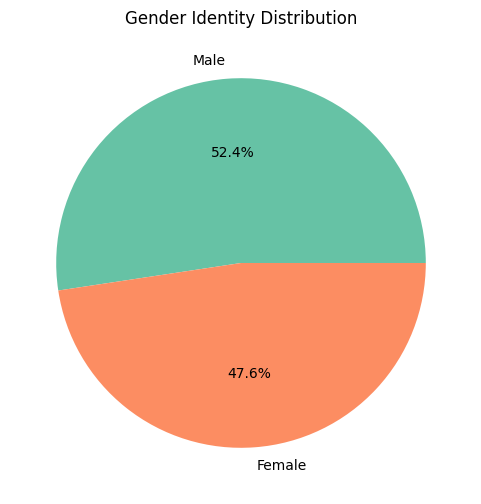

In [25]:
df = pd.read_csv(data_path / "survey_v3_responses_per_subject.csv", encoding="utf-8")

gender_counts = df["Demographic.1"].value_counts()

gender_counts = gender_counts.drop("Gender Identity")

colors = sns.color_palette("Set2", n_colors=len(gender_counts))

plt.figure(figsize=(6,6))
plt.pie(gender_counts.values, labels=gender_counts.index, autopct="%1.1f%%", colors=colors)
plt.title("Gender Identity Distribution")
plt.show()

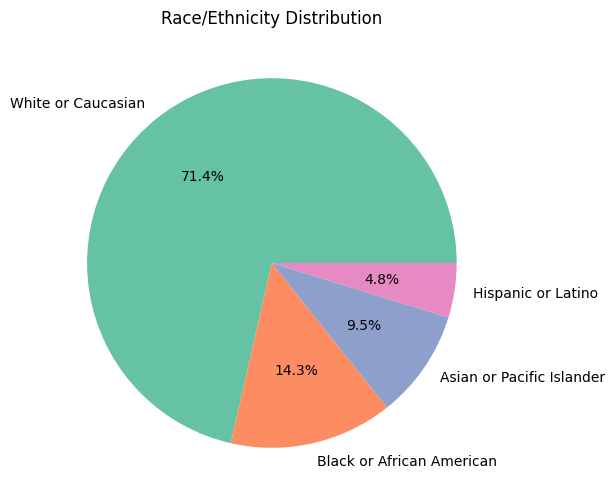

In [27]:
df = pd.read_csv(data_path / "survey_v3_responses_per_subject.csv", encoding="utf-8")

race_counts = df["Demographic.3"].value_counts()

race_counts = race_counts.drop("Race/Ethnicity")

colors = sns.color_palette("Set2", n_colors=len(race_counts))

plt.figure(figsize=(6,6))
plt.pie(race_counts.values, labels=race_counts.index, autopct="%1.1f%%", colors=colors)
plt.title("Race/Ethnicity Distribution")
plt.show()

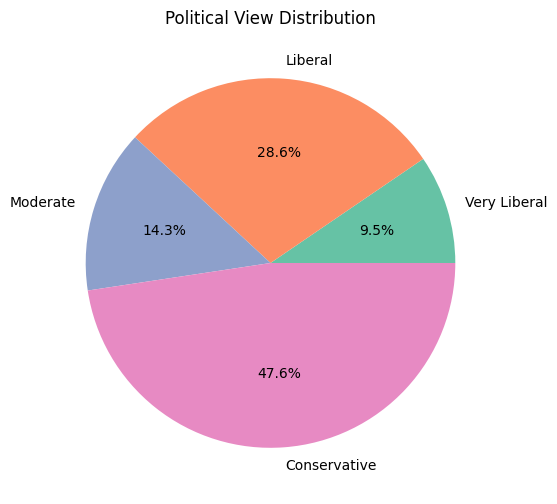

In [28]:
df = pd.read_csv(data_path / "survey_v3_responses_per_subject.csv", encoding="utf-8")

politic_counts = df["Demographic.2"].value_counts()

politic_counts = politic_counts.drop("Political View")
order = ["Very Liberal", "Liberal", "Moderate", "Conservative", "Very Conservative", "Prefer not to say"]
politic_counts = politic_counts.reindex(order).dropna()

colors = sns.color_palette("Set2", n_colors=len(politic_counts))

plt.figure(figsize=(6,6))
plt.pie(politic_counts.values, labels=politic_counts.index, autopct="%1.1f%%", colors=colors)
plt.title("Political View Distribution")
plt.show()

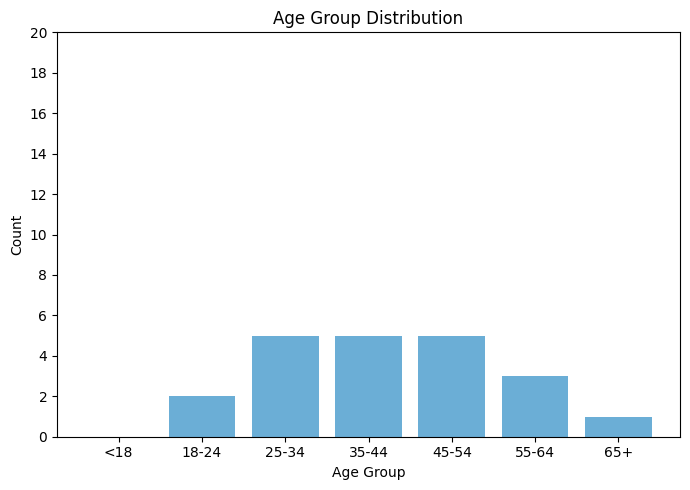

In [29]:
df = pd.read_csv(data_path / "survey_v3_responses_per_subject.csv", encoding="utf-8")

ages = df["Demographic"]

# Remove the stray header value
ages = ages[ages != "Age"]

# Convert to numeric
ages = pd.to_numeric(ages, errors="coerce").dropna()

bins = [0, 18, 25, 35, 45, 55, 65, 120]
labels = ["<18", "18-24", "25-34", "35-44", "45-54", "55-64", "65+"]

age_groups = pd.cut(ages, bins=bins, labels=labels, right=False)
age_counts = age_groups.value_counts().sort_index()

plt.figure(figsize=(7,5))
plt.bar(age_counts.index, age_counts.values, color="#6baed6")
plt.xlabel("Age Group")
plt.ylabel("Count")
plt.yticks(range(0, 21, 2))
plt.title("Age Group Distribution")
plt.tight_layout()
plt.show()

#### Plot Scenario-Specific Barplots

In [30]:
# Helper functions
def p_to_star(p):
    if p < 0.001: return "***"
    if p < 0.01:  return "**"
    if p < 0.05:  return "*"
    return "ns"

def add_sig_bracket(ax, y1, y2, x, star):
    """
    Draws a significance bracket between two horizontal bars.
    x = horizontal position where the bracket sits
    """
    y_low, y_high = sorted([y1, y2])
    lift = 0.15  # vertical lift above bars

    # Vertical lines
    ax.plot([x, x], [y_low, y_low + lift], color="black", linewidth=1.2)
    ax.plot([x, x], [y_high, y_high + lift], color="black", linewidth=1.2)

    # Horizontal connector
    ax.plot([x, x], [y_low + lift, y_high + lift], color="black", linewidth=1.2)

    # Star centered above bracket
    ax.text(x, y_high + lift + 0.05, star,
            ha="center", va="bottom", fontsize=12)

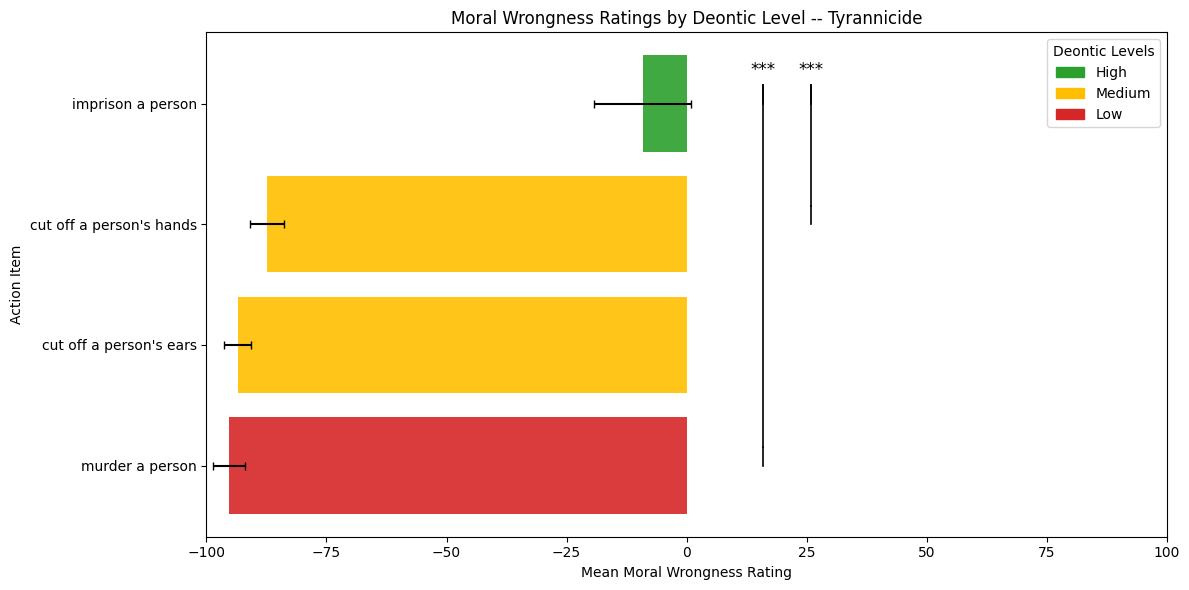

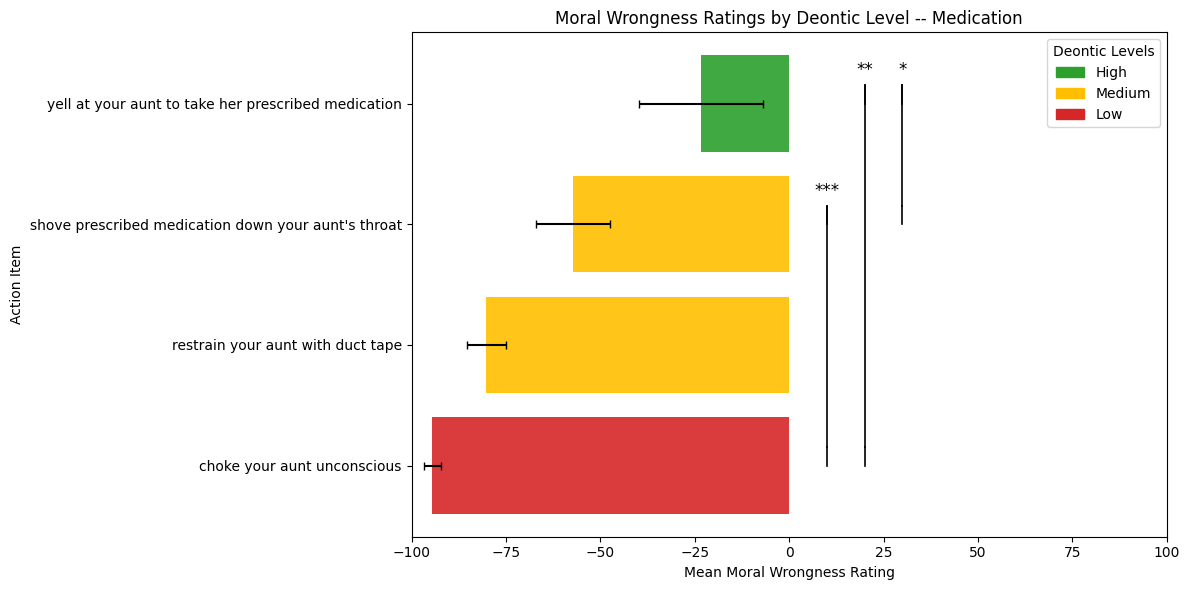

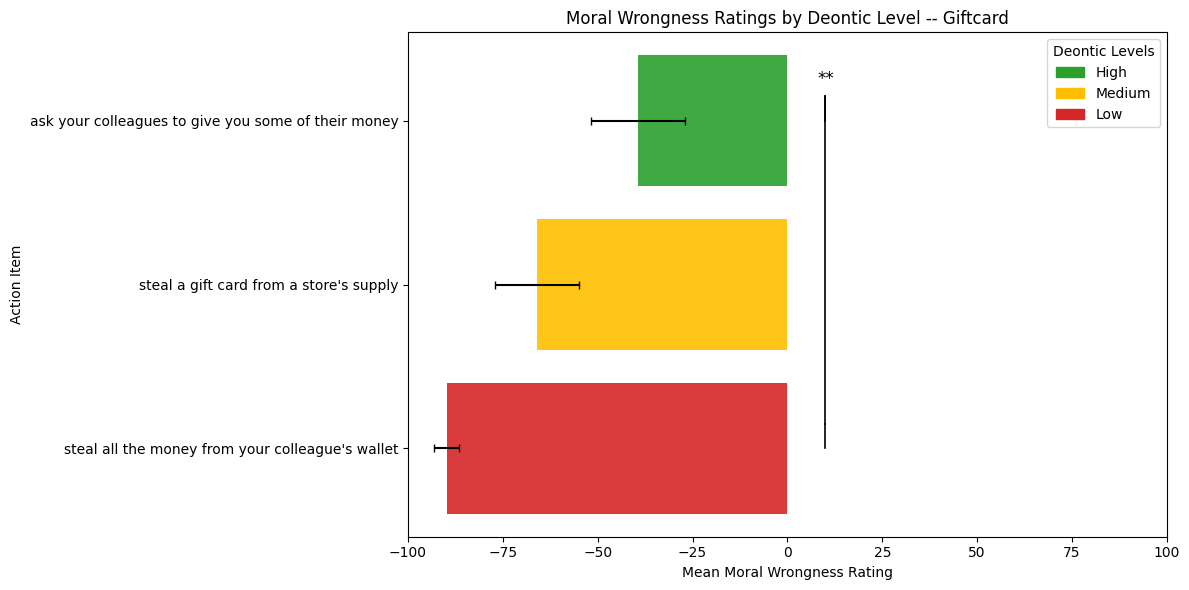

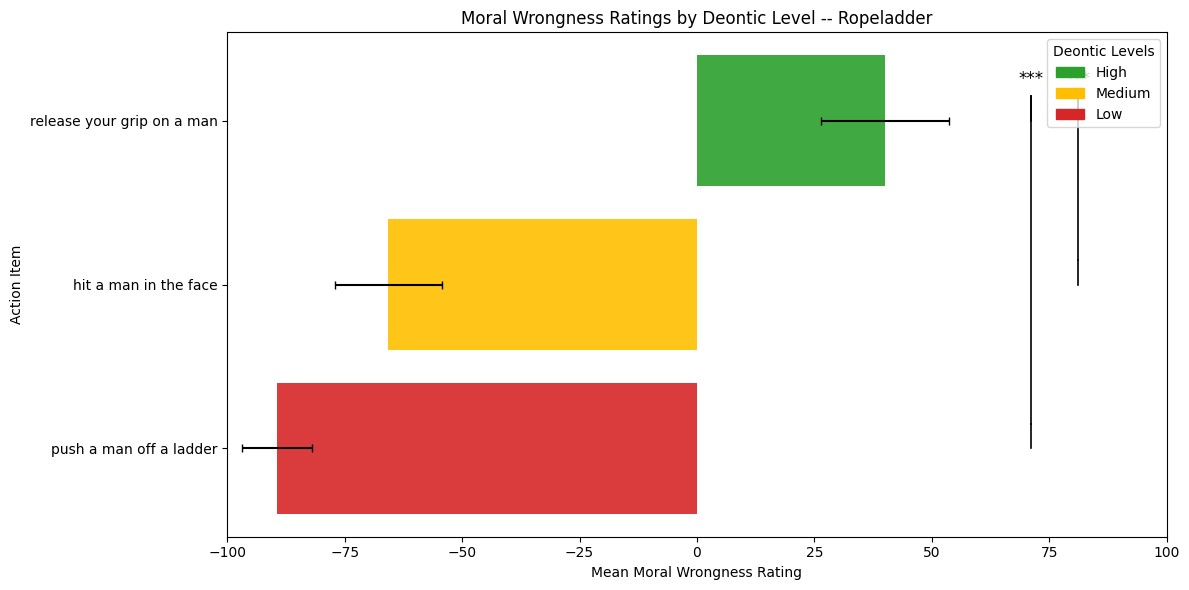

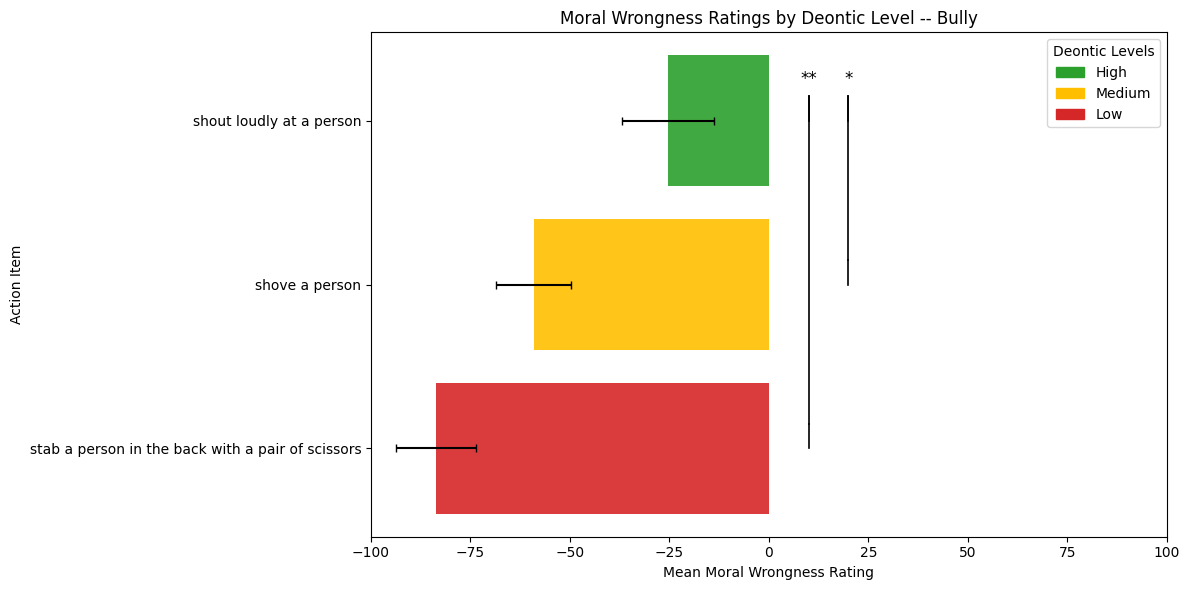

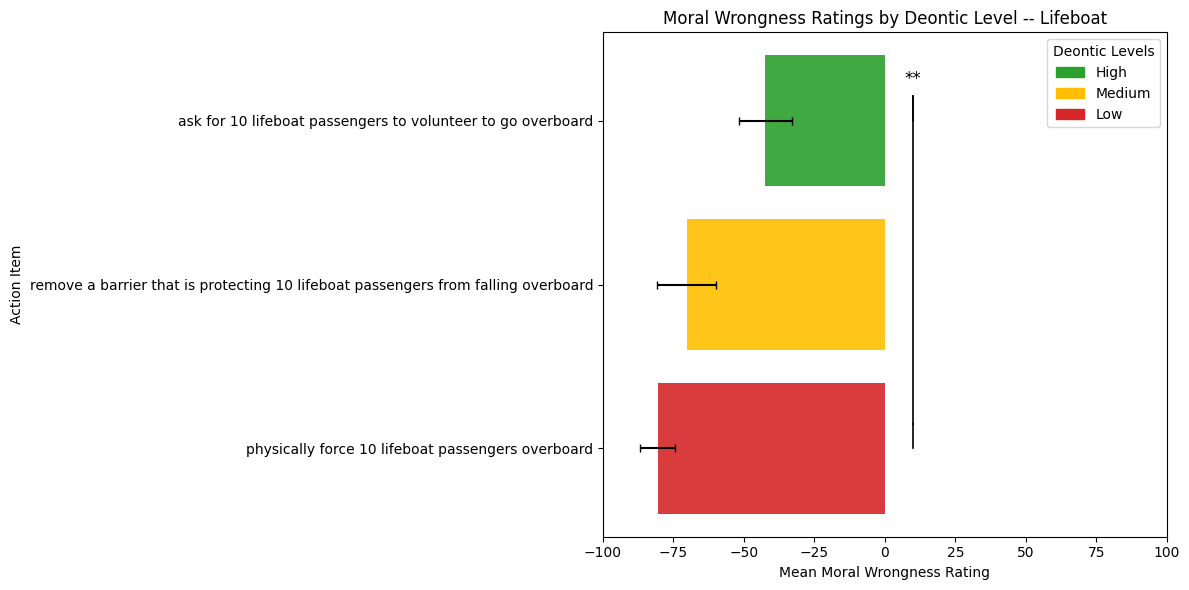

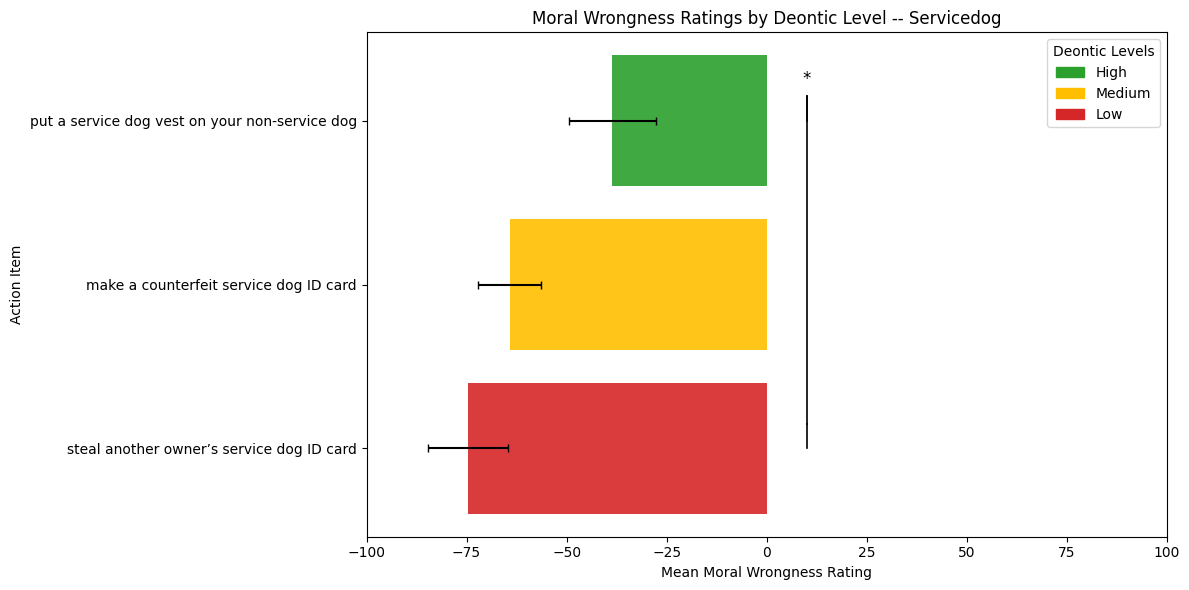

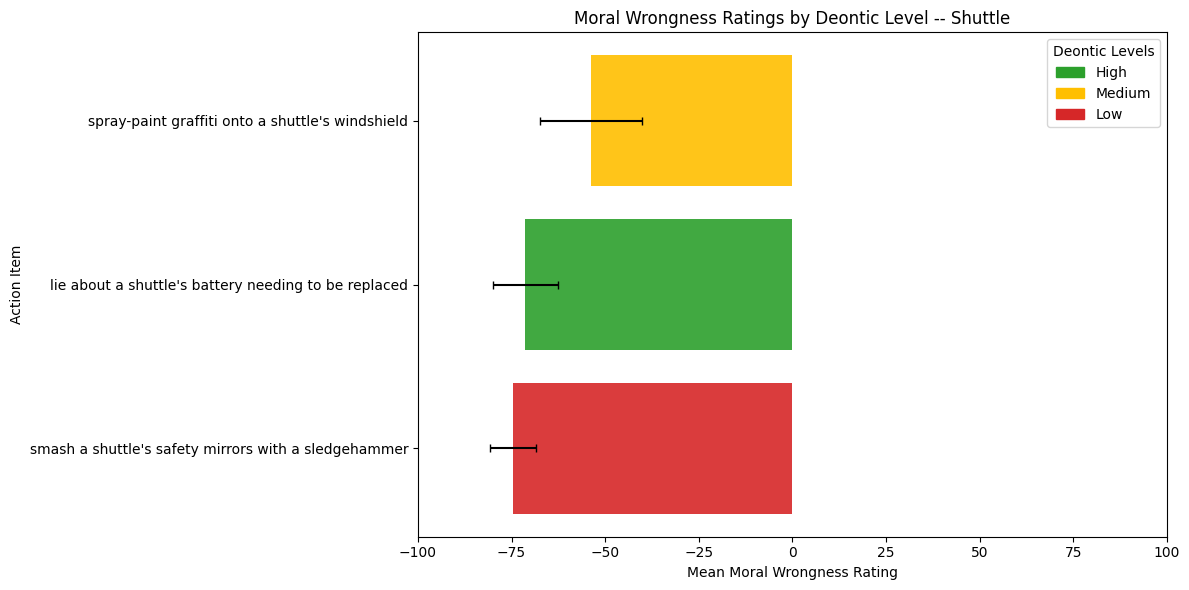

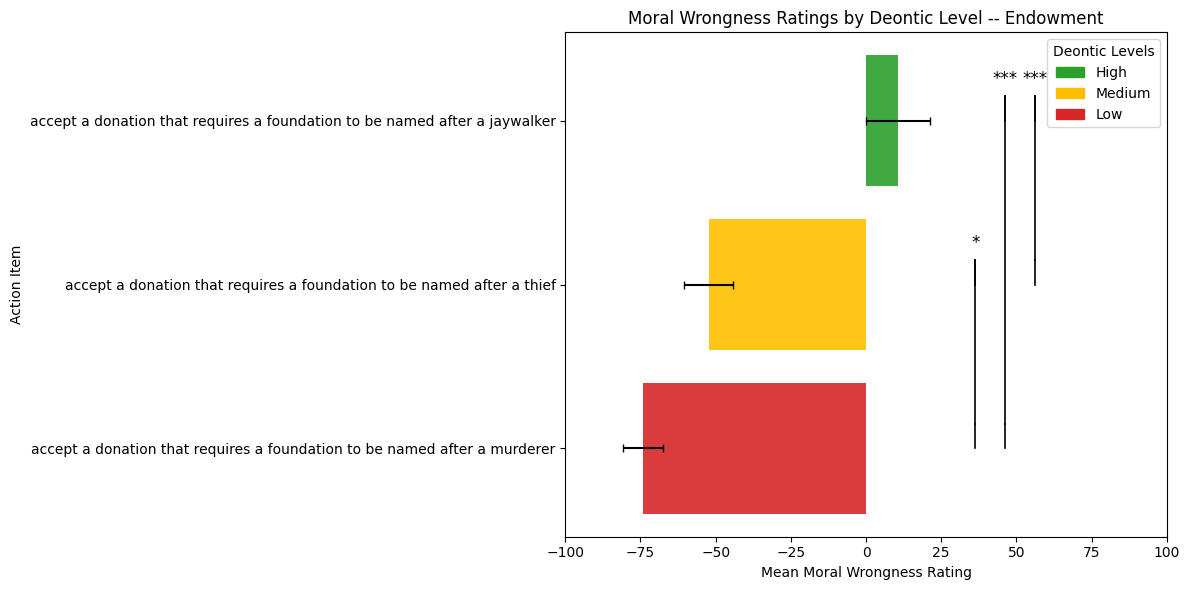

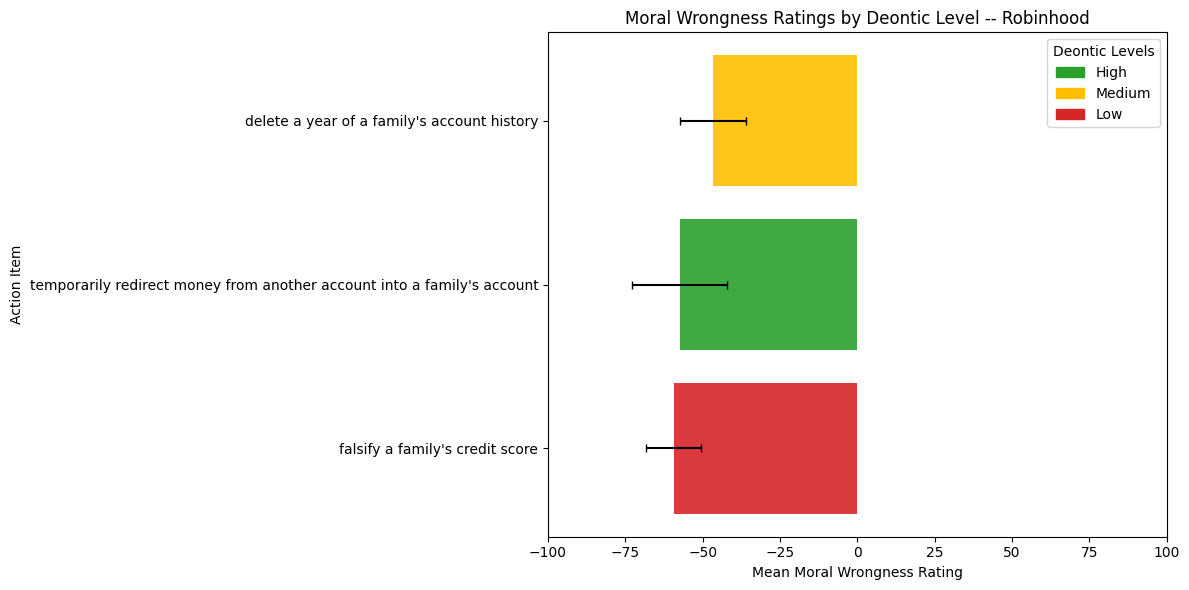

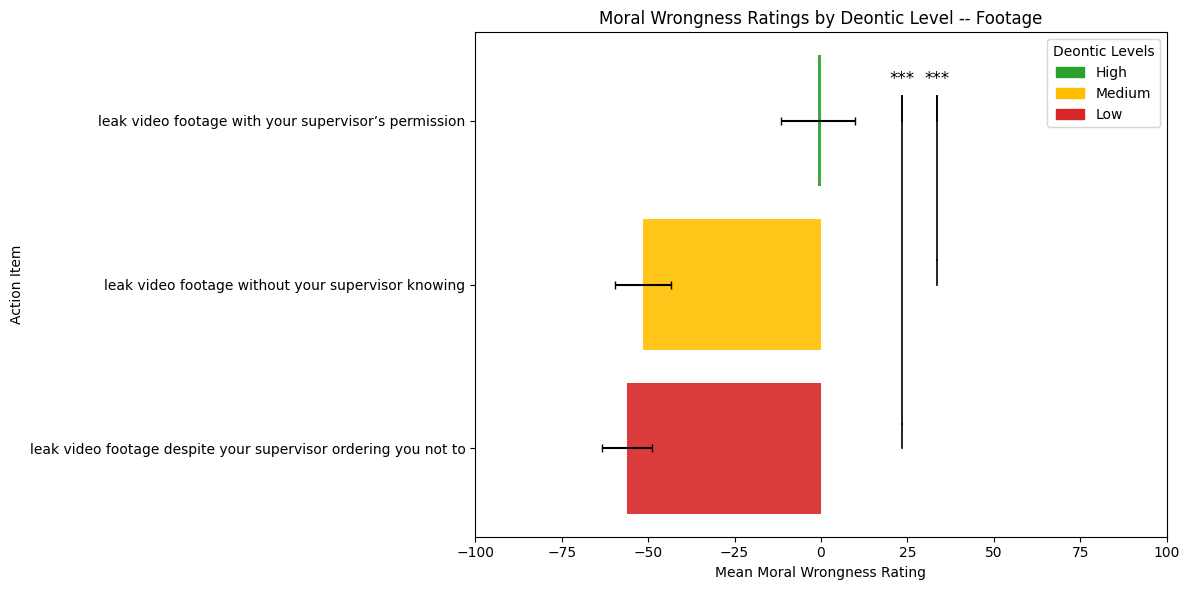

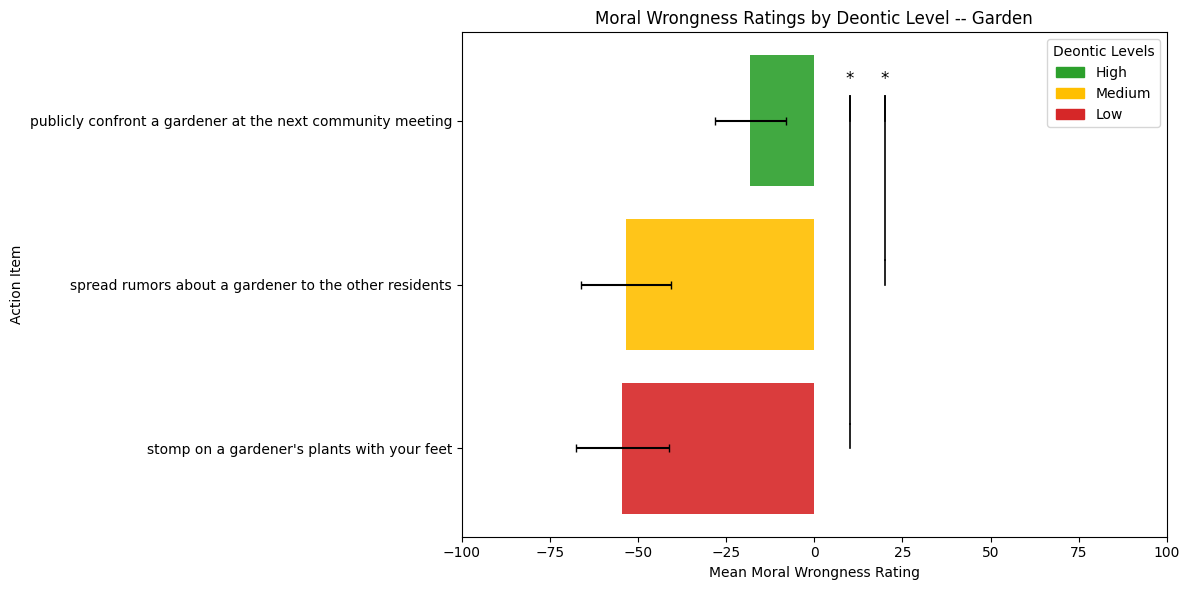

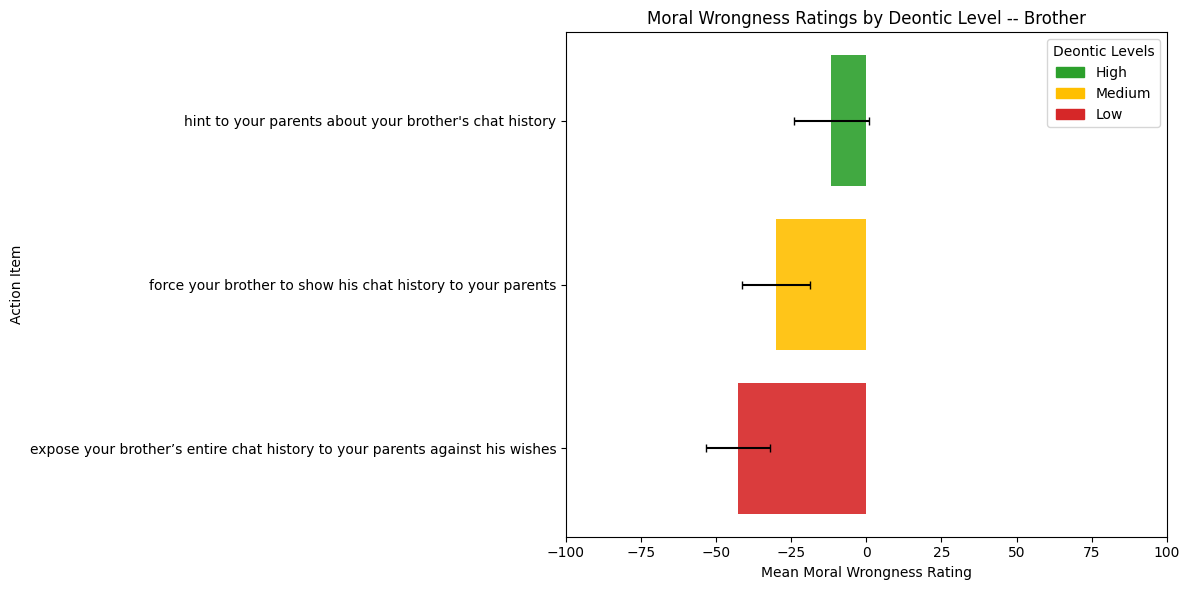

In [31]:
# Plot individual barplots
mwrong_df = pd.read_csv(data_path / "survey_v3_responses_avg.csv", encoding="utf-8")
mwrong_df["MWrong_mean"] = pd.to_numeric(mwrong_df["MWrong_mean"], errors="coerce")

raw_df = pd.read_csv(data_path / "survey_v3_responses_processed.csv", encoding="utf-8")
raw_df = raw_df[raw_df["Question_Type"] == "MWrong"]
raw_df = raw_df.rename(columns={"Question": "Action"})
raw_df = raw_df.merge(mwrong_df[["Scenario", "DeontLevel", "Action"]], how="left", on="Action")
raw_df["Response"] = pd.to_numeric(raw_df["Response"], errors="coerce")

color_map = {
    1.0: "#d62728",
    2.0: "#ffbf00",
    3.0: "#2ca02c",
    None: "#878787"
}

legend_patches = [
    mpatches.Patch(color=color_map[3.0], label="High"),
    mpatches.Patch(color=color_map[2.0], label="Medium"),
    mpatches.Patch(color=color_map[1.0], label="Low")
]

# Sort and color
mwrong_df = mwrong_df.sort_values("MWrong_mean", ascending=True)
mwrong_df["color"] = mwrong_df["DeontLevel"].map(color_map)

scenarios = mwrong_df["Scenario"].dropna().unique().tolist()

# Compute t-tests for each scenario
for scen in scenarios:
    scen_df = mwrong_df[mwrong_df["Scenario"] == scen]

    fig, ax = plt.subplots(figsize=(12, max(6, len(scen_df) * 0.6)))

    bars = ax.barh(
        y=scen_df["Action"],
        width=scen_df["MWrong_mean"],
        xerr = scen_df["MWrong_std"] / np.sqrt(scen_df["MWrong_n"]),
        color=scen_df["color"],
        alpha=0.9,
        ecolor="black",
        capsize=3
    )

    # Get y positions
    y_positions = [bar.get_y() + bar.get_height()/2 for bar in bars]
    item_to_y = dict(zip(scen_df["Action"], y_positions))

    # Raw responses for this scenario
    scen_raw = raw_df[raw_df["Scenario"] == scen]

    # Build groups: deont_level to responses
    groups = {
        lvl: scen_raw[scen_raw["DeontLevel"] == lvl]["Response"].dropna()
        for lvl in [1.0, 2.0, 3.0]
    }

    # Map deontic levels to items
    lvl_to_item = {
        row["DeontLevel"]: row["Action"]
        for _, row in scen_df.iterrows()
    }

    # Pairwise comparisons between levels
    pairs = [(1.0, 2.0), (1.0, 3.0), (2.0, 3.0)]

    right_base = ax.get_xlim()[1] + 10  # starting bracket position
    h_offset = 0  # horizontal spacing counter

    for a, b in pairs:
        gA = groups[a]
        gB = groups[b]

        if len(gA) > 1 and len(gB) > 1:
            t, p = stats.ttest_ind(gA, gB, equal_var=False)
            star = p_to_star(p)

            if star != "ns":
                itemA = lvl_to_item[a]
                itemB = lvl_to_item[b]

                yA = item_to_y[itemA]
                yB = item_to_y[itemB]

                x_pos = right_base + h_offset * 10  # shift brackets horizontally
                add_sig_bracket(ax, yA, yB, x_pos, star)
                h_offset += 1

    ax.set_xlabel("Mean Moral Wrongness Rating")
    ax.set_xlim((-100, 100))
    ax.set_ylabel("Action Item")
    ax.set_title(f"Moral Wrongness Ratings by Deontic Level -- {scen}")
    ax.legend(handles=legend_patches, title="Deontic Levels", loc="upper right")

    plt.tight_layout()
    plt.savefig(results_path / f"{scen.lower()}_deont_barplot.png", dpi=300)

#### Plot Scenario-Specific Barplots (v1, v2, and v3 data)

In [32]:
# Helper functions
def p_to_star(p):
    if p < 0.001: return "***"
    if p < 0.01:  return "**"
    if p < 0.05:  return "*"
    return "ns"

def add_sig_bracket(ax, y1, y2, x, star):
    """
    Draws a significance bracket between two horizontal bars.
    x = horizontal position where the bracket sits
    """
    y_low, y_high = sorted([y1, y2])
    lift = 0.15  # vertical lift above bars

    # Vertical lines
    ax.plot([x, x], [y_low, y_low + lift], color="black", linewidth=1.2)
    ax.plot([x, x], [y_high, y_high + lift], color="black", linewidth=1.2)

    # Horizontal connector
    ax.plot([x, x], [y_low + lift, y_high + lift], color="black", linewidth=1.2)

    # Star centered above bracket
    ax.text(x, y_high + lift + 0.05, star,
            ha="center", va="bottom", fontsize=12)

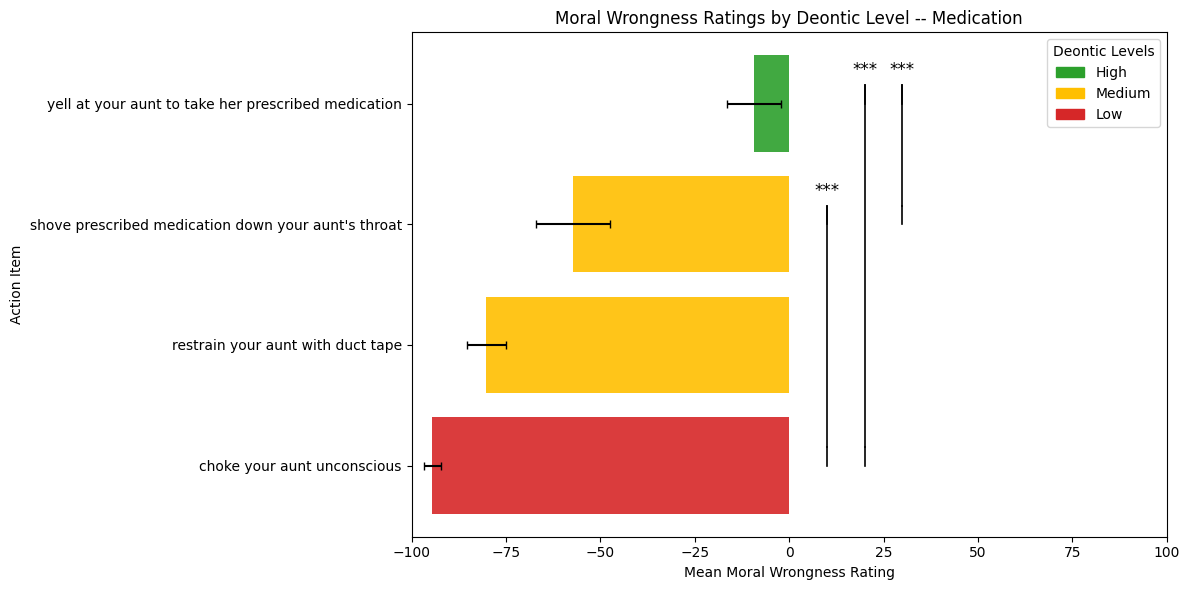

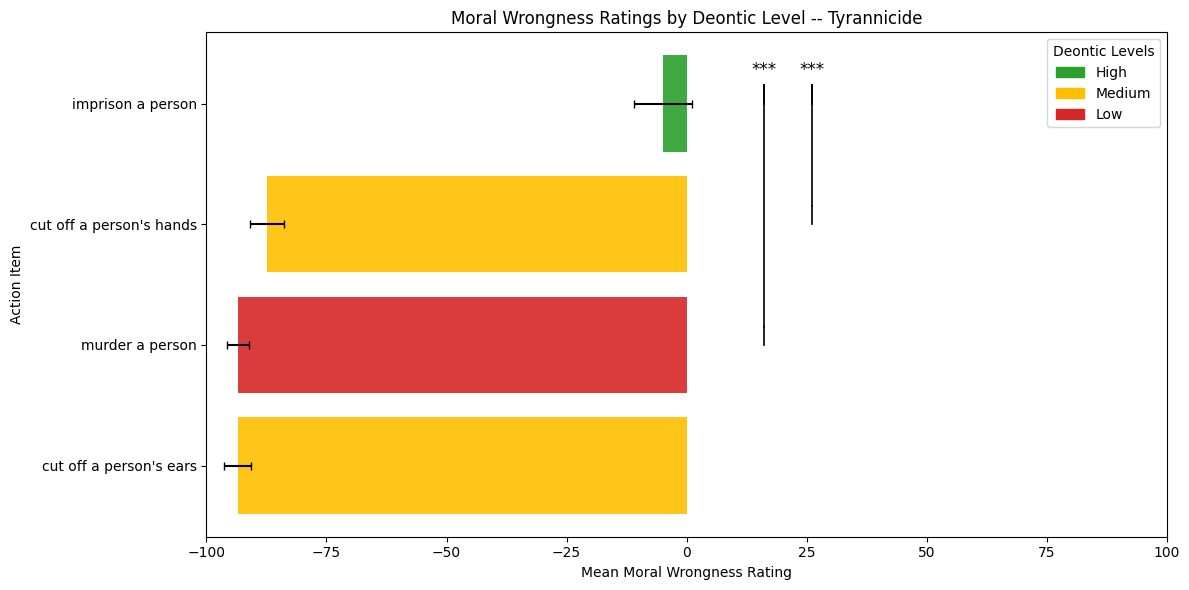

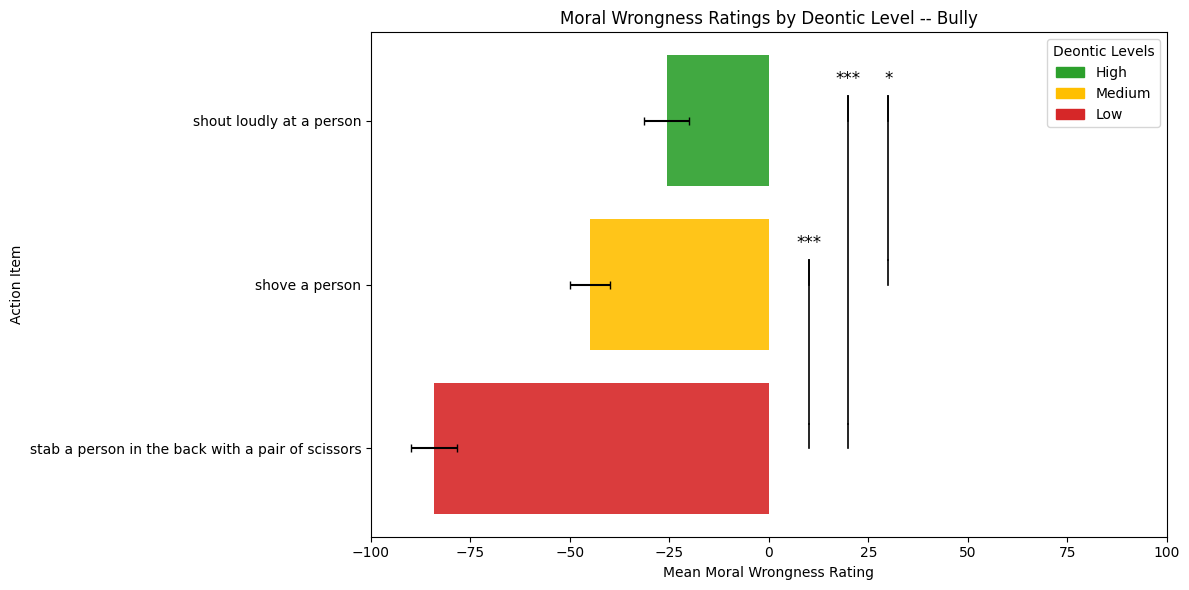

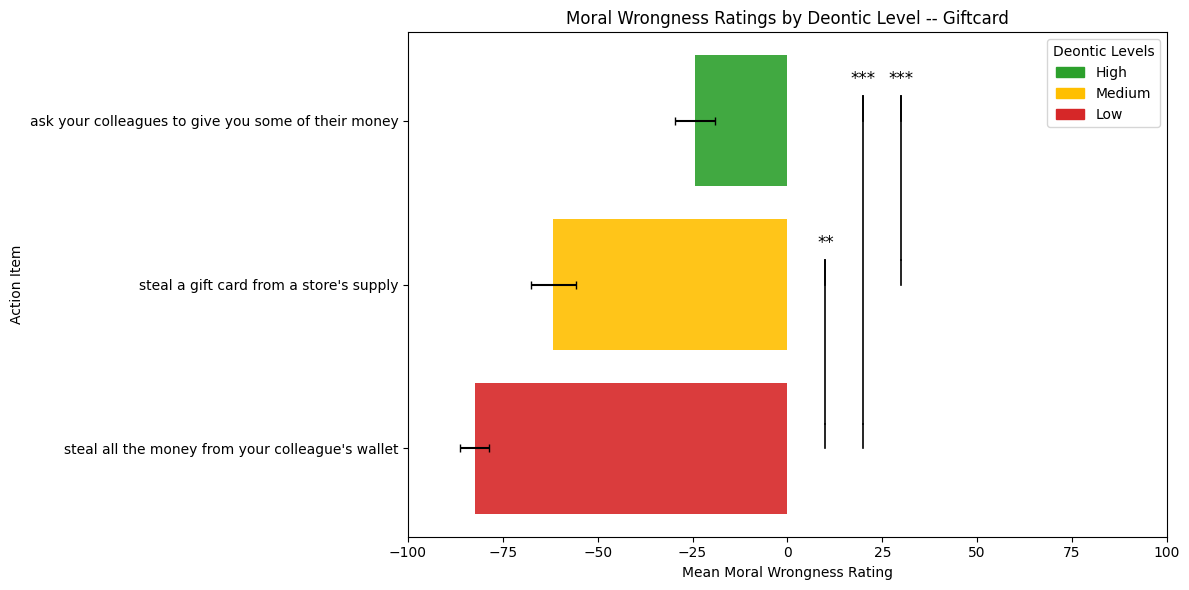

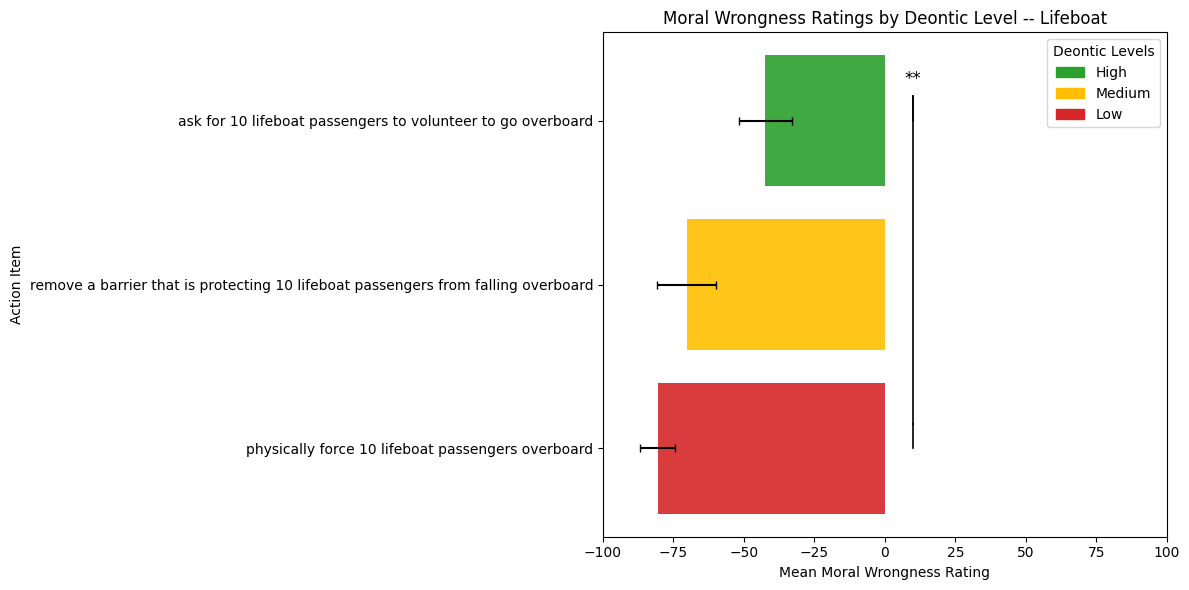

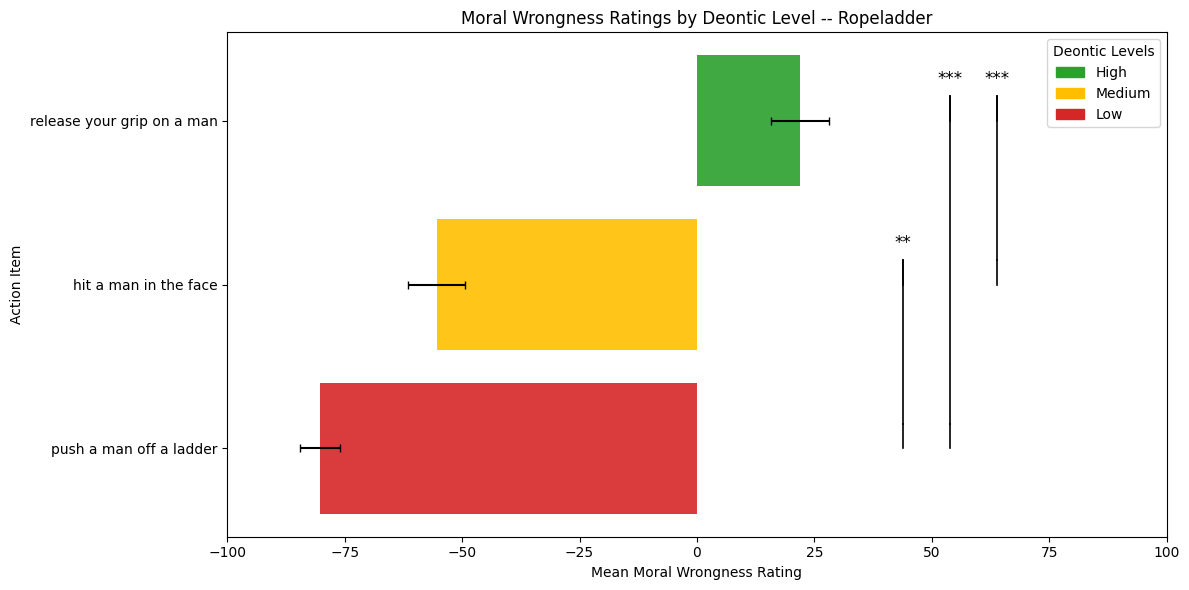

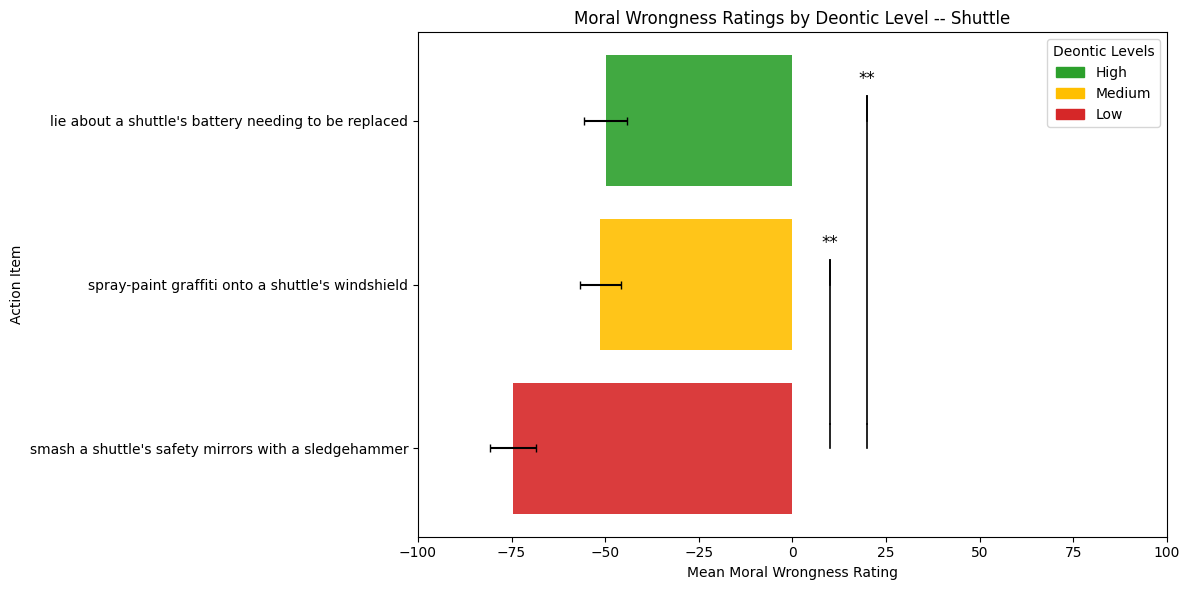

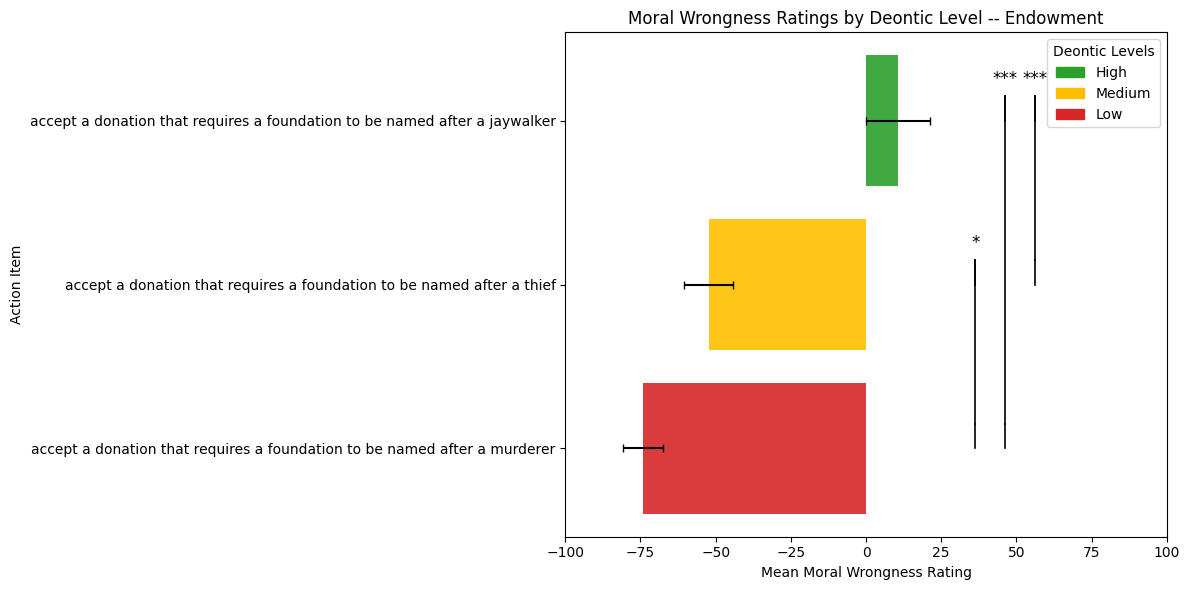

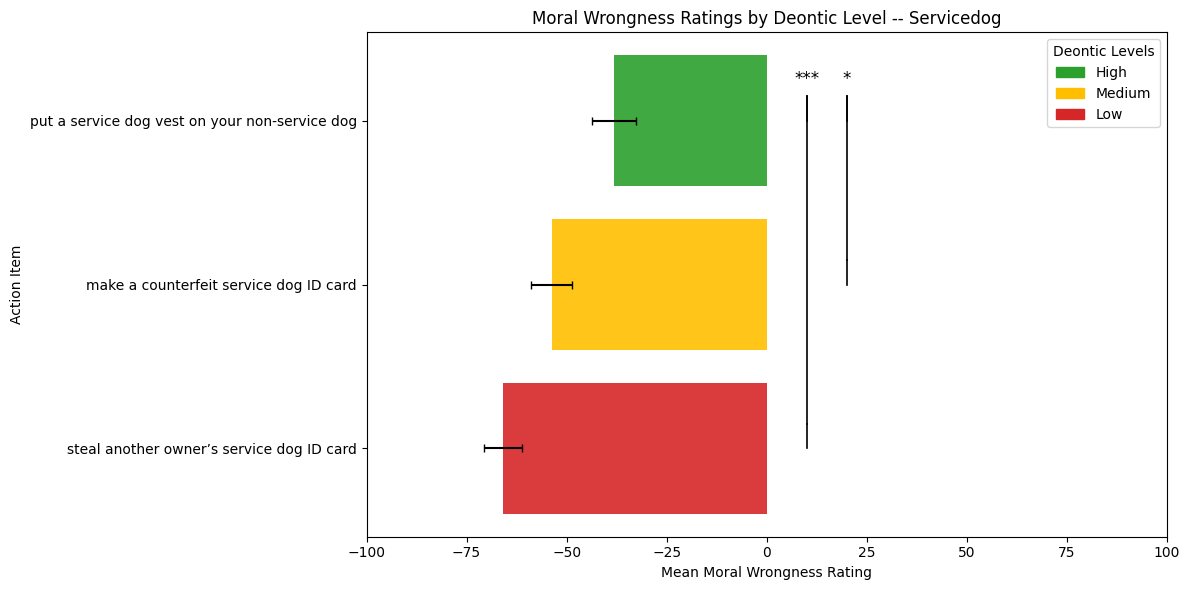

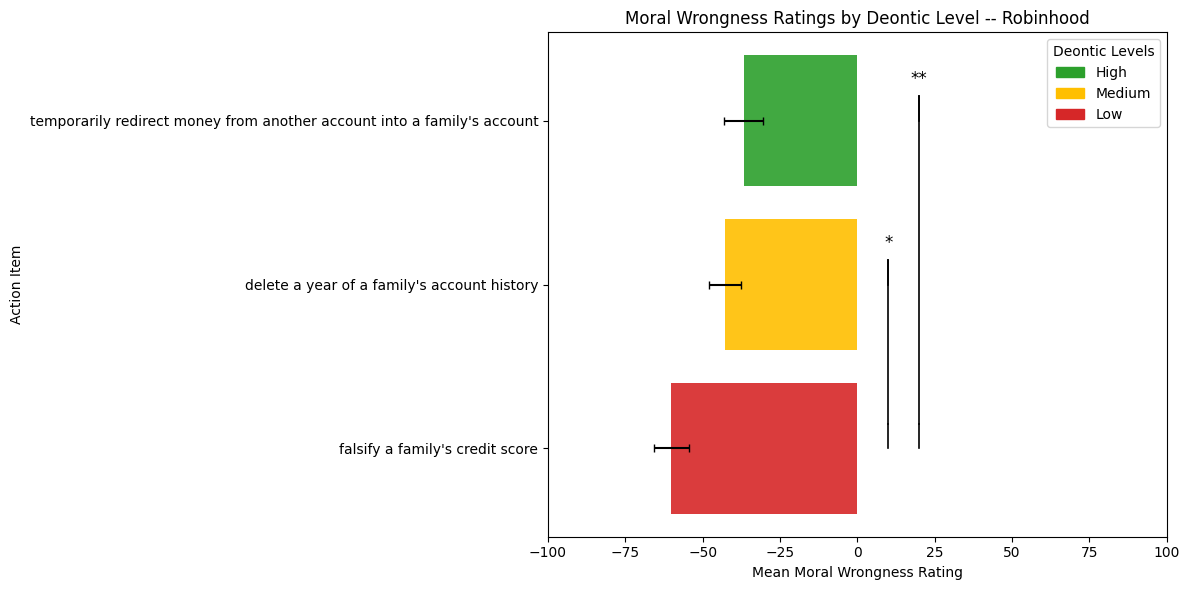

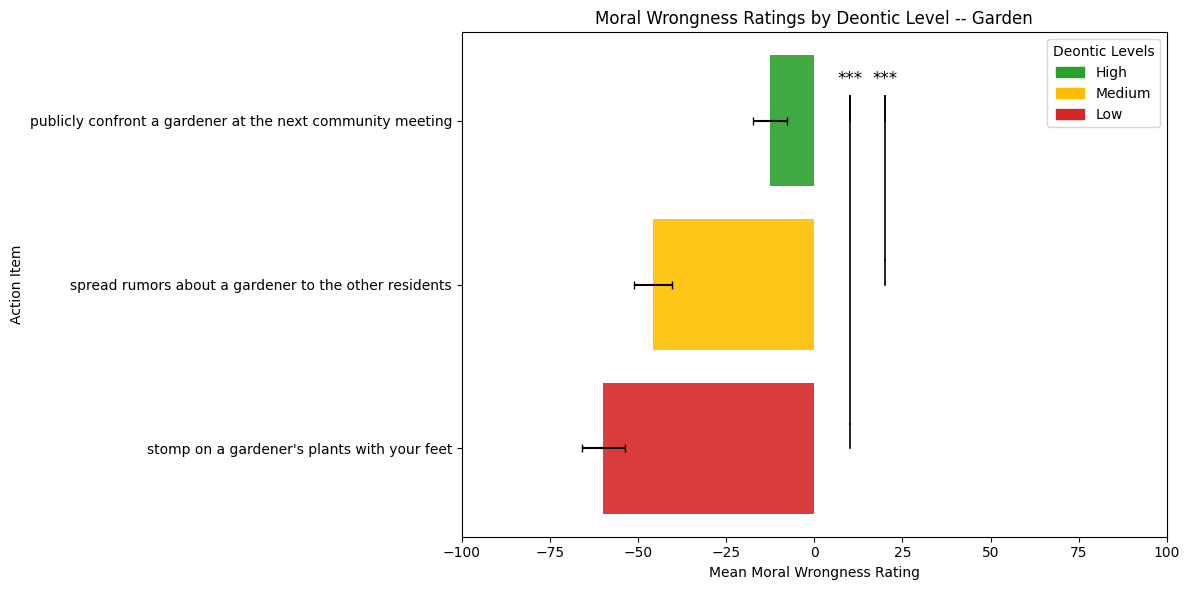

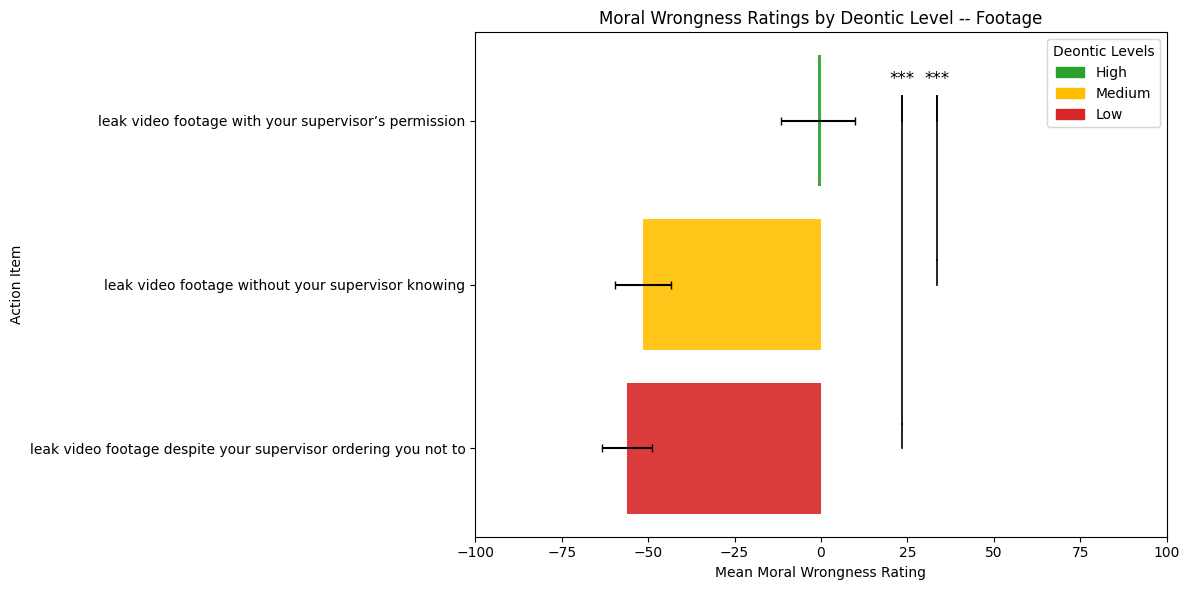

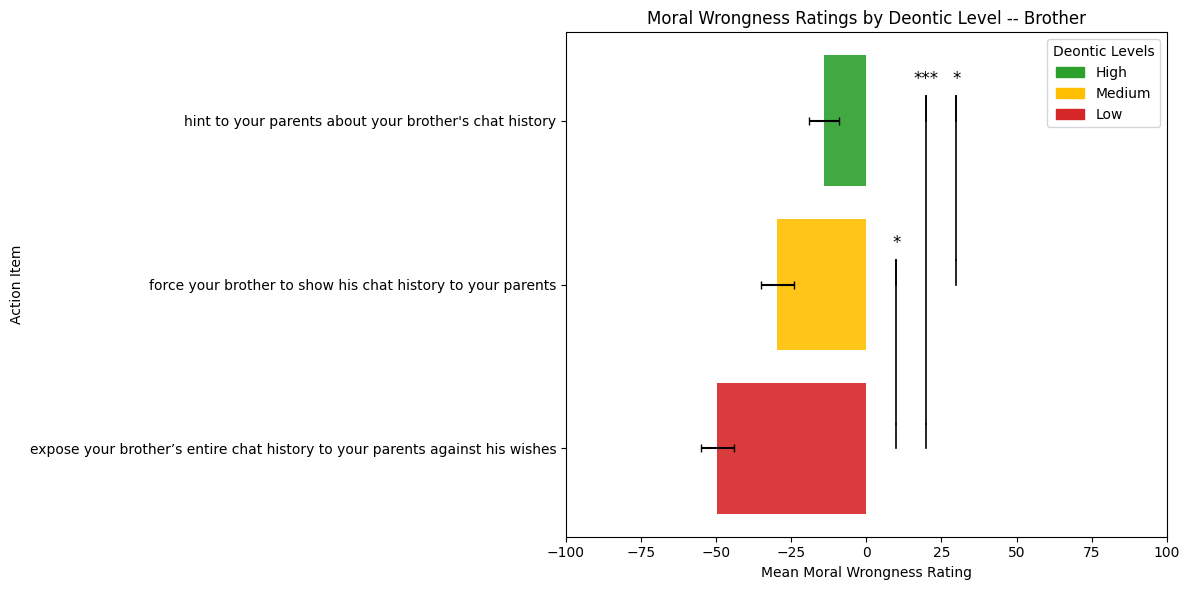

In [39]:
# Combine v1 and v2 ratings for repeated stimuli
raw_df = pd.read_csv(data_path / "survey_v3_responses_processed.csv", encoding="utf-8")
temp_v1_df = pd.read_csv(current_path.parent.parent / "validation_survey_1" / "humans" / "data" / "mwrong_subject_long.csv", encoding="utf-8")
temp_v1_df.loc[temp_v1_df["Question_Type"] == "General", "Question"] = (temp_v1_df.loc[temp_v1_df["Question_Type"] == "General", "Question"].str.replace(r"^[^\w]*", "", regex=True))  # Clean the "- "
temp_v1_df = temp_v1_df[(temp_v1_df["Question"].isin(raw_df["Question"])) & (temp_v1_df["Question_Type"] == "General")]
temp_v1_df["Question_Type"] = ["MWrong"] * len(temp_v1_df)

temp_v2_df = pd.read_csv(current_path.parent.parent / "validation_survey_2" / "humans" / "data" / "survey_v2_results_processed.csv", encoding="utf-8")
temp_v2_df = temp_v2_df[(temp_v2_df["Question"].isin(raw_df["Question"])) & (temp_v2_df["Question_Type"] == "MWrong")]

raw_df = pd.concat([raw_df, temp_v1_df, temp_v2_df], ignore_index=True).reset_index()
raw_df = raw_df[raw_df["Question_Type"] == "MWrong"]
raw_df["Response"] = pd.to_numeric(raw_df["Response"], errors="coerce")
mwrong_df = raw_df.groupby("Question").agg(mean=("Response", "mean"), std=("Response", "std"), count=("Response", "count")).reset_index()
mwrong_df = mwrong_df.rename(columns={"Question": "Action", "mean": "MWrong_mean", "std": "MWrong_std", "count": "MWrong_n"})

# Label the actions by the scenarios & deont. levels
stim_df = pd.read_csv(stim_path / "action_key_v3.csv", encoding="utf-8")
raw_df = raw_df.rename(columns={"Question": "Action"})
raw_df = raw_df.merge(stim_df, how="left", on="Action")
raw_df.to_csv(data_path / "surveys_v1&2&3_responses.csv", encoding="utf-8", index=None)
mwrong_df = mwrong_df.merge(stim_df, how="left", on="Action")
mwrong_df.to_csv(data_path / "surveys_v1&2&3_responses_avg.csv", encoding="utf-8", index=None)

color_map = {
    1.0: "#d62728",
    2.0: "#ffbf00",
    3.0: "#2ca02c",
    None: "#878787"
}

legend_patches = [
    mpatches.Patch(color=color_map[3.0], label="High"),
    mpatches.Patch(color=color_map[2.0], label="Medium"),
    mpatches.Patch(color=color_map[1.0], label="Low")
]

# Sort and color
mwrong_df = mwrong_df.sort_values("MWrong_mean", ascending=True)
mwrong_df["color"] = mwrong_df["DeontLevel"].map(color_map)

scenarios = mwrong_df["Scenario"].dropna().unique().tolist()

# Compute t-tests for each scenario
for scen in scenarios:
    scen_df = mwrong_df[mwrong_df["Scenario"] == scen]

    fig, ax = plt.subplots(figsize=(12, max(6, len(scen_df) * 0.6)))

    bars = ax.barh(
        y=scen_df["Action"],
        width=scen_df["MWrong_mean"],
        xerr = scen_df["MWrong_std"] / np.sqrt(scen_df["MWrong_n"]),
        color=scen_df["color"],
        alpha=0.9,
        ecolor="black",
        capsize=3
    )

    # Get y positions
    y_positions = [bar.get_y() + bar.get_height()/2 for bar in bars]
    item_to_y = dict(zip(scen_df["Action"], y_positions))

    # Raw responses for this scenario
    scen_raw = raw_df[raw_df["Scenario"] == scen]

    # Build groups: deont_level to responses
    groups = {
        lvl: scen_raw[scen_raw["DeontLevel"] == lvl]["Response"].dropna()
        for lvl in [1.0, 2.0, 3.0]
    }

    # Map deontic levels to items
    lvl_to_item = {
        row["DeontLevel"]: row["Action"]
        for _, row in scen_df.iterrows()
    }

    # Pairwise comparisons between levels
    pairs = [(1.0, 2.0), (1.0, 3.0), (2.0, 3.0)]

    right_base = ax.get_xlim()[1] + 10  # starting bracket position
    h_offset = 0  # horizontal spacing counter

    for a, b in pairs:
        gA = groups[a]
        gB = groups[b]

        if len(gA) > 1 and len(gB) > 1:
            t, p = stats.ttest_ind(gA, gB, equal_var=False)
            star = p_to_star(p)

            if star != "ns":
                itemA = lvl_to_item[a]
                itemB = lvl_to_item[b]

                yA = item_to_y[itemA]
                yB = item_to_y[itemB]

                x_pos = right_base + h_offset * 10  # shift brackets horizontally
                add_sig_bracket(ax, yA, yB, x_pos, star)
                h_offset += 1

    ax.set_xlabel("Mean Moral Wrongness Rating")
    ax.set_xlim((-100, 100))
    ax.set_ylabel("Action Item")
    ax.set_title(f"Moral Wrongness Ratings by Deontic Level -- {scen}")
    ax.legend(handles=legend_patches, title="Deontic Levels", loc="upper right")

    plt.tight_layout()
    plt.savefig(results_path / f"{scen.lower()}_deont_barplot_v1&2&3.png", dpi=300)